# Analyse exploratoire sur les donnees synthetiques brutes

Objectif de ce notebook : analyser les donnees brutes PrediCare TPA avant le feature engineering et l'entrainement du modele de detection de fraude.

Ce notebook couvre :
- inventaire des fichiers et controles qualite ;
- verification de la couverture des labels ;
- distribution de la cible `est_fraude` et des `type_fraude` ;
- analyse du desequilibre des classes ;
- identification des colonnes de fuite a exclure du modele ;
- premieres variables discriminantes candidates pour la phase de feature engineering.

## 1. Imports et configuration

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 160)
plt.style.use("default")

In [2]:
def find_project_root(start: Path | None = None) -> Path:
    """Find the repository root from the current notebook location."""
    current = (start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "CohorteAI_datagen-20261011T144733Z-1-001").exists():
            return candidate
    raise FileNotFoundError(
        "Impossible de trouver le dossier CohorteAI_datagen-20261011T144733Z-1-001"
    )


ROOT = find_project_root()
DATA_ROOT = ROOT / "CohorteAI_datagen-20261011T144733Z-1-001" / "CohorteAI_datagen"
DATASET_DIR = DATA_ROOT / "dataset"
LABELS_DIR = DATA_ROOT / "labels"

print("ROOT:", ROOT)
print("DATASET_DIR:", DATASET_DIR)
print("LABELS_DIR:", LABELS_DIR)

ROOT: /home/akemi/Projects/Capstone
DATASET_DIR: /home/akemi/Projects/Capstone/CohorteAI_datagen-20261011T144733Z-1-001/CohorteAI_datagen/dataset
LABELS_DIR: /home/akemi/Projects/Capstone/CohorteAI_datagen-20261011T144733Z-1-001/CohorteAI_datagen/labels


## 2. Chargement des donnees

In [4]:
date_cols_factures = ["date_soin", "date_facture", "date_reception", "date_traitement"]
date_cols_ordonnances = ["date_prescription"]
date_cols_assures = ["date_adhesion", "date_radiation"]
date_cols_contrats = ["date_effet_police", "date_effet", "date_fin"]
date_cols_prestataires = ["date_conventionnement", "date_fin_convention"]

factures = pd.read_csv(DATASET_DIR / "factures.csv", parse_dates=date_cols_factures)
lignes_facture = pd.read_csv(DATASET_DIR / "lignes_facture.csv")
ordonnances = pd.read_csv(DATASET_DIR / "ordonnances.csv", parse_dates=date_cols_ordonnances)
ordonnance_lignes = pd.read_csv(DATASET_DIR / "ordonnance_lignes.csv")
assures = pd.read_csv(DATASET_DIR / "assures.csv", parse_dates=date_cols_assures)
prestataires = pd.read_csv(DATASET_DIR / "prestataires.csv", parse_dates=date_cols_prestataires)
contrats = pd.read_csv(DATASET_DIR / "contrats.csv", parse_dates=date_cols_contrats)
garanties = pd.read_csv(DATASET_DIR / "garanties.csv")
grille_tarifaire = pd.read_csv(DATASET_DIR / "grille_tarifaire.csv")
referentiel_actes = pd.read_csv(DATASET_DIR / "referentiel_actes.csv")
referentiel_medicaments = pd.read_csv(DATASET_DIR / "referentiel_medicaments.csv")

labels_fraude = pd.read_csv(LABELS_DIR / "labels_fraude.csv")
labels_prestataires = pd.read_csv(LABELS_DIR / "labels_prestataires.csv")

In [5]:
tables = {
    "factures": factures,
    "lignes_facture": lignes_facture,
    "ordonnances": ordonnances,
    "ordonnance_lignes": ordonnance_lignes,
    "assures": assures,
    "prestataires": prestataires,
    "contrats": contrats,
    "garanties": garanties,
    "grille_tarifaire": grille_tarifaire,
    "referentiel_actes": referentiel_actes,
    "referentiel_medicaments": referentiel_medicaments,
    "labels_fraude": labels_fraude,
    "labels_prestataires": labels_prestataires,
}

inventaire = pd.DataFrame(
    [{"table": name, "lignes": len(df), "colonnes": df.shape[1]} for name, df in tables.items()]
).sort_values("lignes", ascending=False)
inventaire

,table,lignes,colonnes
1,lignes_facture,123270,9
0,factures,84593,24
11,labels_fraude,84593,6
3,ordonnance_lignes,82175,6
2,ordonnances,47804,8
4,assures,4459,9
8,grille_tarifaire,3242,3
6,contrats,1500,12
5,prestataires,251,20
12,labels_prestataires,251,2


## 3. Controles qualite generaux

In [7]:
def quality_summary(df: pd.DataFrame, key: str | None = None) -> pd.Series:
    return pd.Series(
        {
            "lignes": len(df),
            "colonnes": df.shape[1],
            "cellules_manquantes": int(df.isna().sum().sum()),
            "colonnes_avec_na": int((df.isna().sum() > 0).sum()),
            "doublons_lignes": int(df.duplicated().sum()),
            "doublons_cle": int(df[key].duplicated().sum())
            if key and key in df.columns
            else np.nan,
        }
    )


keys = {
    "factures": "facture_id",
    "lignes_facture": "ligne_id",
    "ordonnances": "ordonnance_id",
    "assures": "assure_id",
    "prestataires": "prestataire_id",
    "contrats": "contrat_id",
    "labels_fraude": "facture_id",
    "labels_prestataires": "prestataire_id",
}

qualite = pd.DataFrame({name: quality_summary(df, keys.get(name)) for name, df in tables.items()}).T
qualite

,lignes,colonnes,cellules_manquantes,colonnes_avec_na,doublons_lignes,doublons_cle
factures,84593.0,24.0,274983.0,5.0,0.0,0.0
lignes_facture,123270.0,9.0,0.0,0.0,0.0,0.0
ordonnances,47804.0,8.0,382.0,2.0,0.0,0.0
ordonnance_lignes,82175.0,6.0,6793.0,1.0,0.0,NaN
assures,4459.0,9.0,4130.0,1.0,0.0,0.0
prestataires,251.0,20.0,587.0,3.0,0.0,0.0
contrats,1500.0,12.0,1391.0,1.0,0.0,0.0
garanties,27.0,11.0,9.0,1.0,0.0,NaN
grille_tarifaire,3242.0,3.0,0.0,0.0,0.0,NaN
referentiel_actes,58.0,12.0,89.0,2.0,0.0,NaN


In [8]:
missing_factures = factures.isna().sum().loc[lambda s: s > 0].sort_values(ascending=False)
missing_factures.to_frame("nb_valeurs_manquantes")

,nb_valeurs_manquantes
entente_prealable_id,84265
motif_rejet,82601
attestation_pec_id,67603
ordonnance_id,37688
date_traitement,2826


In [9]:
controle_labels = pd.Series(
    {
        "factures": len(factures),
        "labels": len(labels_fraude),
        "labels_sans_facture": int(
            (~labels_fraude["facture_id"].isin(factures["facture_id"])).sum()
        ),
        "factures_sans_label": int(
            (~factures["facture_id"].isin(labels_fraude["facture_id"])).sum()
        ),
        "doublons_facture_id_labels": int(labels_fraude["facture_id"].duplicated().sum()),
    }
)
controle_labels.to_frame("valeur")

,valeur
factures,84593
labels,84593
labels_sans_facture,0
factures_sans_label,0
doublons_facture_id_labels,0


In [10]:
factures_labeled = factures.merge(labels_fraude, on="facture_id", how="left", validate="one_to_one")
factures_labeled = factures_labeled.merge(
    labels_prestataires, on="prestataire_id", how="left", validate="many_to_one"
)
factures_labeled["est_suspect"] = factures_labeled["est_suspect"].fillna(0).astype(int)

factures_labeled.shape

(84593, 30)

## 4. Distribution de la cible et desequilibre

In [11]:
target_counts = labels_fraude["est_fraude"].value_counts().sort_index()
target_rate = labels_fraude["est_fraude"].mean()

pd.DataFrame(
    {
        "classe": ["non_fraude", "fraude"],
        "nombre": [target_counts.get(0, 0), target_counts.get(1, 0)],
        "proportion": [1 - target_rate, target_rate],
    }
)

,classe,nombre,proportion
0,non_fraude,77246,0.913149
1,fraude,7347,0.086851


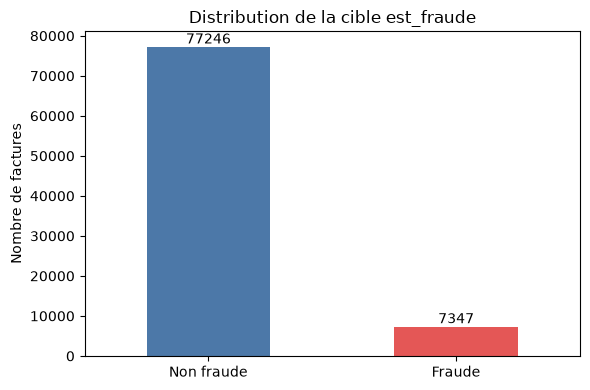

In [12]:
fig, ax = plt.subplots(figsize=(6, 4))
target_counts.rename({0: "Non fraude", 1: "Fraude"}).plot(
    kind="bar", ax=ax, color=["#4C78A8", "#E45756"]
)
ax.set_title("Distribution de la cible est_fraude")
ax.set_xlabel("")
ax.set_ylabel("Nombre de factures")
ax.bar_label(ax.containers[0])
plt.xticks(rotation=0)
plt.tight_layout()

In [13]:
type_fraude_counts = labels_fraude["type_fraude"].dropna().value_counts()
type_fraude_counts.to_frame("nombre")

,nombre
type_fraude,
SURFACTURATION,1272
DOUBLON,909
UPCODING,742
LIGNES_NON_PRESCRITES,733
QUANTITE_EXCESSIVE,568
ORDONNANCE_EXPIREE,502
ACTE_FICTIF,496
SURCONSOMMATION,469
INCOHERENCE_PROFIL,379


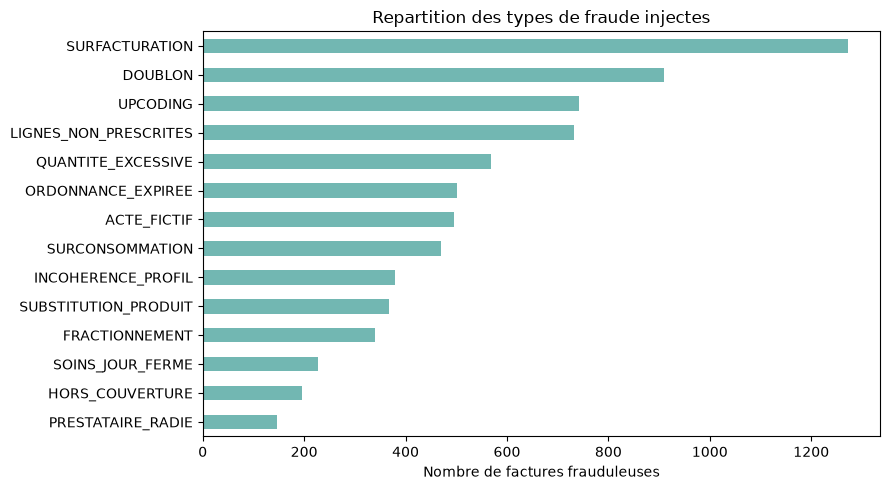

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))
type_fraude_counts.sort_values().plot(kind="barh", ax=ax, color="#72B7B2")
ax.set_title("Repartition des types de fraude injectes")
ax.set_xlabel("Nombre de factures frauduleuses")
ax.set_ylabel("")
plt.tight_layout()

**Lecture attendue :** la fraude est minoritaire. Le modele devra donc etre evalue avec des metriques adaptees au desequilibre : rappel, precision, F1, PR-AUC, matrice de confusion et cout metier des faux positifs/faux negatifs. SMOTE ou une ponderation de classe ne doivent etre appliques que sur le jeu d'entrainement.

## 5. Analyse temporelle

In [15]:
dates_summary = pd.DataFrame(
    {
        "min": factures[["date_soin", "date_facture", "date_reception", "date_traitement"]].min(),
        "max": factures[["date_soin", "date_facture", "date_reception", "date_traitement"]].max(),
    }
)
dates_summary

,min,max
date_soin,2024-10-01,2026-10-01
date_facture,2024-10-01,2026-10-05
date_reception,2024-10-02,2026-11-20
date_traitement,2024-10-06,2026-10-03


In [16]:
monthly = (
    factures_labeled.assign(
        mois_soin=factures_labeled["date_soin"].dt.to_period("M").dt.to_timestamp()
    )
    .groupby("mois_soin")
    .agg(
        nb_factures=("facture_id", "count"),
        nb_fraudes=("est_fraude", "sum"),
        taux_fraude=("est_fraude", "mean"),
        montant_total=("montant_total", "sum"),
    )
)
monthly.tail()

,nb_factures,nb_fraudes,taux_fraude,montant_total
mois_soin,,,,
2026-06-01,3777,303,0.080222,143664150
2026-07-01,3252,298,0.091636,119218050
2026-08-01,3214,295,0.091786,134530200
2026-09-01,3619,284,0.078475,133729150
2026-10-01,1,1,1.000000,35000


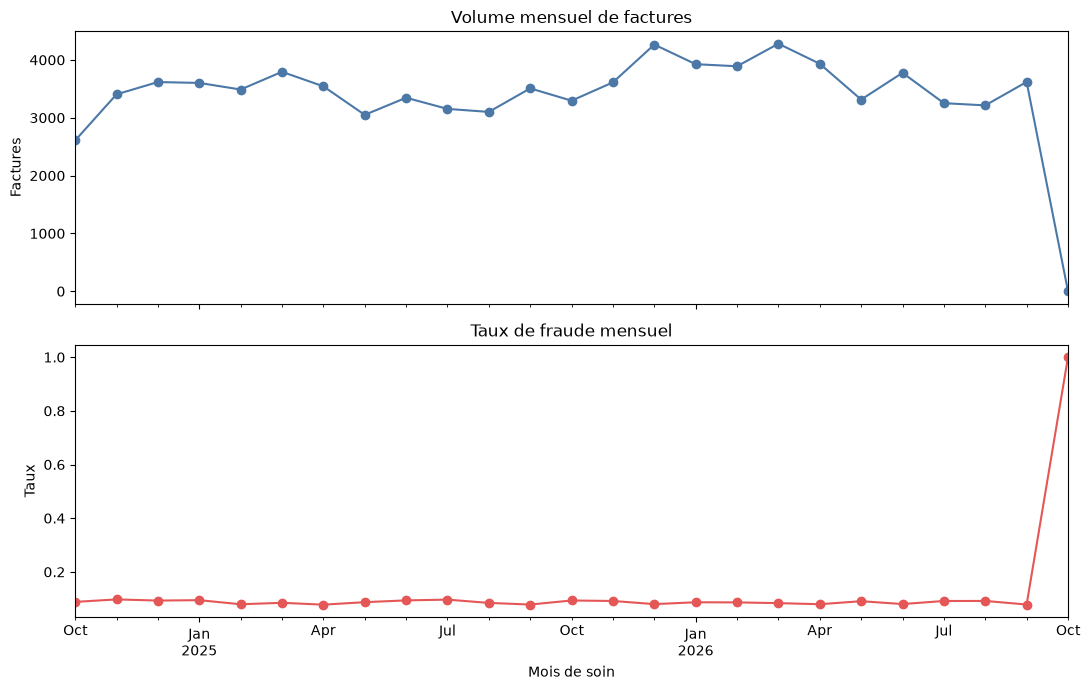

In [17]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
monthly["nb_factures"].plot(ax=axes[0], marker="o", color="#4C78A8")
axes[0].set_title("Volume mensuel de factures")
axes[0].set_ylabel("Factures")
monthly["taux_fraude"].plot(ax=axes[1], marker="o", color="#E45756")
axes[1].set_title("Taux de fraude mensuel")
axes[1].set_ylabel("Taux")
axes[1].set_xlabel("Mois de soin")
plt.tight_layout()

## 6. Analyse par type de facture et variables metier

In [18]:
def fraud_rate_by(df: pd.DataFrame, col: str, min_count: int = 1) -> pd.DataFrame:
    result = (
        df.groupby(col, dropna=False)["est_fraude"]
        .agg(nb_factures="count", nb_fraudes="sum", taux_fraude="mean")
        .query("nb_factures >= @min_count")
        .sort_values("taux_fraude", ascending=False)
    )
    return result


fraude_par_type_facture = fraud_rate_by(factures_labeled, "type_facture")
fraude_par_type_facture

,nb_factures,nb_fraudes,taux_fraude
type_facture,,,
KINESITHERAPIE,789,193,0.244613
MATERNITE,766,157,0.204961
OPTIQUE,546,91,0.166667
DENTAIRE,1966,283,0.143947
HOSPITALISATION,513,60,0.116959
IMAGERIE,2611,304,0.116430
PHARMACIE,32488,3087,0.095020
LABORATOIRE,10306,970,0.094120
CONSULTATION,34608,2202,0.063627


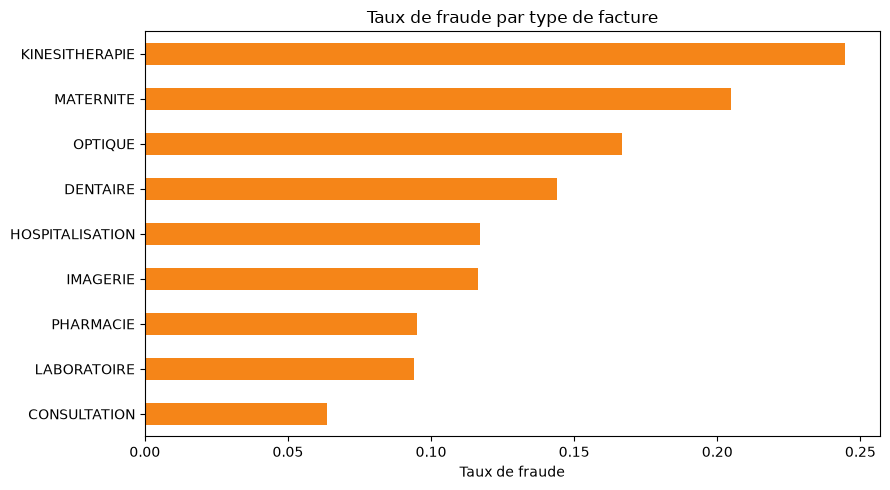

In [19]:
fig, ax = plt.subplots(figsize=(9, 5))
fraude_par_type_facture["taux_fraude"].sort_values().plot(kind="barh", ax=ax, color="#F58518")
ax.set_title("Taux de fraude par type de facture")
ax.set_xlabel("Taux de fraude")
ax.set_ylabel("")
plt.tight_layout()

In [20]:
for col in ["canal_reception", "mode_reglement", "devise", "est_suspect"]:
    display(fraud_rate_by(factures_labeled, col))

,nb_factures,nb_fraudes,taux_fraude
canal_reception,,,
EMAIL,17034,1567,0.091992
PORTAIL_PRESTATAIRE,25371,2291,0.090300
PAPIER_SCAN,42188,3489,0.082701


,nb_factures,nb_fraudes,taux_fraude
mode_reglement,,,
REMBOURSEMENT_ASSURE,4973,495,0.099538
TIERS_PAYANT,79620,6852,0.086059


,nb_factures,nb_fraudes,taux_fraude
devise,,,
MGA,84593,7347,0.086851


,nb_factures,nb_fraudes,taux_fraude
est_suspect,,,
1,4802,1697,0.353394
0,79791,5650,0.070810


In [21]:
factures_enrichies = (
    factures_labeled.merge(
        assures[["assure_id", "sexe", "annee_naissance", "ville"]].rename(
            columns={"ville": "ville_assure"}
        ),
        on="assure_id",
        how="left",
    )
    .merge(
        prestataires[
            [
                "prestataire_id",
                "type_prestataire",
                "ville",
                "niveau_tarif",
                "note_qualite",
                "statut",
            ]
        ].rename(columns={"ville": "ville_prestataire", "statut": "statut_prestataire"}),
        on="prestataire_id",
        how="left",
    )
    .merge(
        contrats[["contrat_id", "formule", "secteur", "statut"]].rename(
            columns={"statut": "statut_contrat"}
        ),
        on="contrat_id",
        how="left",
    )
)

for col in [
    "ville_assure",
    "type_prestataire",
    "ville_prestataire",
    "niveau_tarif",
    "formule",
    "secteur",
]:
    display(fraud_rate_by(factures_enrichies, col, min_count=50).head(20))

,nb_factures,nb_fraudes,taux_fraude
ville_assure,,,
Fianarantsoa,3691,381,0.103224
Toamasina,6369,610,0.095776
Antananarivo,60660,5243,0.086433
Mahajanga,4155,359,0.086402
Toliara,2856,246,0.086134
Antsiranana,1266,99,0.078199
Antsirabe,5596,409,0.073088


,nb_factures,nb_fraudes,taux_fraude
type_prestataire,,,
OPTICIEN,546,91,0.166667
CABINET_DENTAIRE,1966,283,0.143947
CABINET_KINE,183,22,0.120219
MATERNITE,155,18,0.116129
CLINIQUE,16470,1783,0.108257
PHARMACIE,32488,3087,0.095020
CENTRE_IMAGERIE,1783,122,0.068424
CABINET_GENERALISTE,20551,1352,0.065788
LABORATOIRE,5755,356,0.061859


,nb_factures,nb_fraudes,taux_fraude
ville_prestataire,,,
Fianarantsoa,2907,316,0.108703
Mahajanga,4068,419,0.102999
Toamasina,6248,554,0.088668
Antananarivo,62909,5491,0.087285
Antsiranana,454,36,0.079295
Toliara,2435,163,0.066940
Antsirabe,5572,368,0.066045


,nb_factures,nb_fraudes,taux_fraude
niveau_tarif,,,
ELEVE,22530,2728,0.121083
TRES_ELEVE,7462,607,0.081345
RAISONNABLE,54601,4012,0.073479


,nb_factures,nb_fraudes,taux_fraude
formule,,,
CONFORT,18357,1680,0.091518
ESSENTIEL,46721,4150,0.088825
PREMIUM,19515,1517,0.077735


,nb_factures,nb_fraudes,taux_fraude
secteur,,,
Commerce & distribution,3370,321,0.095252
Transport & logistique,10913,994,0.091084
Agro-alimentaire,10099,919,0.090999
Services aux entreprises,3692,335,0.090737
Particulier,10793,971,0.089966
Mines & énergie,3294,287,0.087128
Télécommunications,6510,547,0.084025
Conseil & audit,10078,846,0.083945
Industrie textile,7983,667,0.083553


## 7. Analyse des montants et des lignes

In [23]:
montant_cols = [
    "montant_total",
    "montant_eligible",
    "montant_pris_en_charge",
    "reste_a_charge",
    "nb_lignes",
]
factures_labeled[montant_cols].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
montant_total,84593.0,38201.318667,145916.425112,500.0,2000.0,5100.0,11900.0,20500.0,32000.0,78000.0,275080.00,7271000.0
montant_eligible,84593.0,37228.799061,140684.539380,0.0,2000.0,5100.0,11800.0,20500.0,31500.0,73500.0,261500.00,6400000.0
montant_pris_en_charge,84593.0,28212.672171,99589.988282,0.0,0.0,0.0,9360.0,17120.0,25600.0,59400.0,199100.80,6400000.0
reste_a_charge,84593.0,9988.646496,80214.803235,0.0,0.0,0.0,810.0,2800.0,5100.0,28500.0,96689.92,7271000.0
nb_lignes,84593.0,1.457213,0.664633,1.0,1.0,1.0,1.0,1.0,2.0,3.0,3.00,6.0


In [24]:
factures_labeled.groupby("est_fraude")[montant_cols].agg(["count", "mean", "median", "std", "max"])

montant_total                                                montant_eligible                                                 \
                   count          mean   median            std      max            count          mean   median            std      max   
est_fraude                                                                                                                                
0                  77246  35294.279315  20500.0  137177.632487  4752000            77246  35080.945292  20500.0  134352.281511  4369500   
1                   7347  68765.788757  38500.0  215139.475943  7271000             7347  59811.228937  35000.0  193777.408193  6400000   

           montant_pris_en_charge                                                reste_a_charge                                               nb_lignes  \
                            count          mean   median            std      max          count          mean  median            std      max     count   
est_fraude                                                                                                                                                
0                           77246  27258.698962  16800.0   95189.183456  3922550          77246   8035.580354  2400.0   68427.295052  4655000     77246   
1                            7347  38242.700014  22800.0  137196.369509  6400000           7347  30523.088744  8500.0  156196.774117  7271000      7347   

                                           
                mean median       std max  
est_fraude                                 
0           1.433679    1.0  0.622405   4  
1           1.704641    1.0  0.972748   6

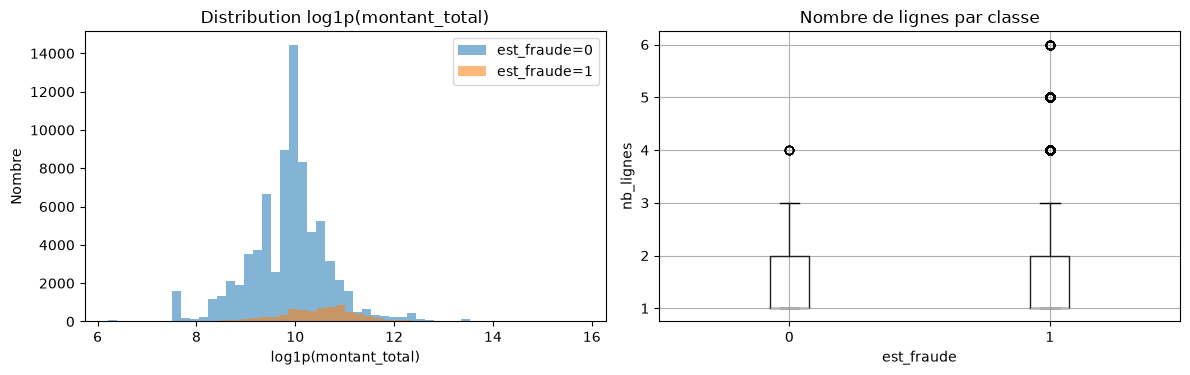

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for label, subset in factures_labeled.groupby("est_fraude"):
    axes[0].hist(
        np.log1p(subset["montant_total"]), bins=50, alpha=0.55, label=f"est_fraude={label}"
    )
axes[0].set_title("Distribution log1p(montant_total)")
axes[0].set_xlabel("log1p(montant_total)")
axes[0].set_ylabel("Nombre")
axes[0].legend()

factures_labeled.boxplot(column="nb_lignes", by="est_fraude", ax=axes[1])
axes[1].set_title("Nombre de lignes par classe")
axes[1].set_xlabel("est_fraude")
axes[1].set_ylabel("nb_lignes")
plt.suptitle("")
plt.tight_layout()

In [25]:
lignes_labeled = lignes_facture.merge(
    labels_fraude[["facture_id", "est_fraude", "type_fraude"]], on="facture_id", how="left"
)

display(lignes_labeled["type_ligne"].value_counts(dropna=False).to_frame("nombre"))
display(
    lignes_labeled.groupby(["type_ligne", "est_fraude"])[
        ["quantite", "prix_unitaire", "montant"]
    ].agg(["count", "mean", "median", "max"])
)

,nombre
type_ligne,
ACTE,61794
MEDICAMENT,61476


quantite                      prix_unitaire                                 montant                                
                         count      mean median max         count          mean   median      max   count          mean   median      max
type_ligne est_fraude                                                                                                                    
ACTE       0             56232  1.110524    1.0  12         56232  35867.127259  21500.0  3369500   56232  41556.805733  22000.0  3369500
           1              5562  1.234448    1.0  17          5562  63678.766631  33500.0  5464500    5562  72445.577131  35000.0  5464500
MEDICAMENT 0             54514  1.160711    1.0   2         54514   6313.570826   5000.0    47700   54514   7145.313131   5200.0    47700
           1              6962  1.522264    1.0  16          6962  11122.055444   6400.0   112500    6962  14691.173513   7400.0   263400

In [26]:
top_montants = factures_labeled.sort_values("montant_total", ascending=False).head(20)
top_montants[
    [
        "facture_id",
        "type_facture",
        "date_soin",
        "prestataire_id",
        "assure_id",
        "montant_total",
        "nb_lignes",
        "est_fraude",
        "type_fraude",
    ]
]

,facture_id,type_facture,date_soin,prestataire_id,assure_id,montant_total,nb_lignes,est_fraude,type_fraude
72994,FAC-00073124,HOSPITALISATION,2026-02-14,PRE-00155,ASS-55126CEE23,7271000,3,1,SURFACTURATION
62967,FAC-00063081,HOSPITALISATION,2026-03-19,PRE-00142,ASS-9D3008254E,6792500,3,1,SURFACTURATION
3992,FAC-00004002,HOSPITALISATION,2025-12-16,PRE-00146,ASS-271489CD31,6307000,3,1,SURFACTURATION
3010,FAC-00003018,MATERNITE,2025-07-12,PRE-00155,ASS-2C1F8CCA1F,4808500,1,1,SURFACTURATION
22481,FAC-00022526,HOSPITALISATION,2025-02-15,PRE-00143,ASS-27AA0637D7,4752000,3,0,NaN
46299,FAC-00046385,HOSPITALISATION,2026-09-01,PRE-00143,ASS-5838F3D373,4704500,3,0,NaN
382,FAC-00000387,HOSPITALISATION,2025-06-06,PRE-00143,ASS-608724F7EF,4655000,3,0,NaN
49533,FAC-00049623,HOSPITALISATION,2026-06-06,PRE-00145,ASS-03DC39BB20,4220500,3,0,NaN
31759,FAC-00031823,HOSPITALISATION,2025-11-28,PRE-00145,ASS-5DCE0C3838,4187500,3,1,QUANTITE_EXCESSIVE
26813,FAC-00026870,HOSPITALISATION,2025-11-08,PRE-00144,ASS-0E7F6BA45A,4174500,3,0,NaN


## 8. Fuites de donnees a exclure du modele

D'apres le dictionnaire des donnees, les colonnes suivantes resultent de la decision historique et ne doivent pas etre utilisees comme variables d'entree du modele :

- `statut` ;
- `motif_rejet` ;
- `montant_pris_en_charge` ;
- `date_traitement`.

Elles peuvent etre analysees pour comprendre les donnees, mais elles doivent etre retirees avant l'entrainement.

In [27]:
leakage_check = fraud_rate_by(factures_labeled, "statut")
leakage_check

,nb_factures,nb_fraudes,taux_fraude
statut,,,
REJETEE,1992,1389,0.697289
EN_COURS,2826,249,0.088110
PAYEE,79775,5709,0.071564


In [28]:
fraud_rate_by(factures_labeled, "motif_rejet")

,nb_factures,nb_fraudes,taux_fraude
motif_rejet,,,
CONTROLE_MEDICAL,998,998,1.000000
ORDONNANCE_PERIMEE,246,246,1.000000
HORS_PERIODE_COUVERTURE,69,69,1.000000
PRODUIT_NON_REMBOURSABLE,3,3,1.000000
ENTENTE_PREALABLE_ABSENTE,15,9,0.600000
PLAFOND_ATTEINT,51,17,0.333333
DELAI_DE_CARENCE,151,20,0.132450
NaN,82601,5958,0.072130
PIECE_MANQUANTE_ATTESTATION,459,27,0.058824


**Lecture attendue :** si une colonne de decision historique explique trop directement la fraude, elle cree une fuite. Le modele doit predire au moment de la reception de la facture, avant la decision de paiement/rejet.

## 9. Signaux metier simples a prototyper

In [29]:
# Comparaison simple prix facture vs grille tarifaire prestataire.
lignes_prix = lignes_labeled.merge(
    factures[["facture_id", "prestataire_id", "date_soin", "type_facture"]],
    on="facture_id",
    how="left",
).merge(
    grille_tarifaire.rename(columns={"tarif_pratique": "tarif_grille"}),
    on=["prestataire_id", "code"],
    how="left",
)

lignes_prix["ratio_prix_grille"] = lignes_prix["prix_unitaire"] / lignes_prix["tarif_grille"]
lignes_prix["ecart_prix_grille"] = lignes_prix["prix_unitaire"] - lignes_prix["tarif_grille"]

lignes_prix[["ratio_prix_grille", "ecart_prix_grille"]].describe(
    percentiles=[0.5, 0.9, 0.95, 0.99]
).T

,count,mean,std,min,50%,90%,95%,99%,max
ratio_prix_grille,122768.0,1.034064,0.336807,0.621118,1.0,1.0,1.0,2.289301,1.311842e+01
ecart_prix_grille,122768.0,1359.053255,24537.186368,-39000.000000,0.0,0.0,0.0,22800.000000,3.443500e+06


In [30]:
lignes_prix.groupby("est_fraude")[["ratio_prix_grille", "ecart_prix_grille"]].agg(
    ["count", "mean", "median", "max"]
)

ratio_prix_grille                             ecart_prix_grille                               
                       count      mean median        max             count         mean median        max
est_fraude                                                                                               
0                     110746  1.008057    1.0   8.352113            110746   690.381594    0.0   755000.0
1                      12022  1.273634    1.0  13.118421             12022  7518.819664    0.0  3443500.0

In [31]:
# Ordonnances reutilisees : signal potentiel de surconsommation.
reutilisation_ordonnance = (
    factures_labeled.dropna(subset=["ordonnance_id"])
    .groupby("ordonnance_id")
    .agg(
        nb_factures=("facture_id", "count"),
        nb_fraudes=("est_fraude", "sum"),
        taux_fraude=("est_fraude", "mean"),
    )
    .sort_values(["nb_factures", "taux_fraude"], ascending=False)
)

display(reutilisation_ordonnance.head(20))
display(
    reutilisation_ordonnance.groupby(
        pd.cut(reutilisation_ordonnance["nb_factures"], bins=[0, 1, 2, 3, 5, 10, 100])
    )["taux_fraude"].agg(["count", "mean"])
)

,nb_factures,nb_fraudes,taux_fraude
ordonnance_id,,,
ORD-0047513,9,8,0.888889
ORD-0047530,9,8,0.888889
ORD-0047561,9,8,0.888889
ORD-0047540,8,8,1.000000
ORD-0047503,8,7,0.875000
ORD-0047504,8,7,0.875000
ORD-0047543,8,7,0.875000
ORD-0047590,7,7,1.000000
ORD-0047501,7,6,0.857143


,count,mean
nb_factures,,
"(0, 1]",44501,0.071122
"(1, 2]",824,0.399879
"(2, 3]",44,0.871212
"(3, 5]",39,0.806410
"(5, 10]",67,0.858298


In [32]:
# Doublons potentiels : meme assure, meme prestataire, meme date de soin, meme montant.
dup_keys = ["assure_id", "prestataire_id", "date_soin", "montant_total"]
doublons_potentiels = factures_labeled.assign(
    nb_meme_signature=factures_labeled.groupby(dup_keys)["facture_id"].transform("count")
)

display(doublons_potentiels["nb_meme_signature"].describe())
display(
    doublons_potentiels.groupby(doublons_potentiels["nb_meme_signature"].clip(upper=5))[
        "est_fraude"
    ].agg(["count", "sum", "mean"])
)

count    84593.000000
mean         1.016242
std          0.128632
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max          3.000000
Name: nb_meme_signature, dtype: float64

,count,sum,mean
nb_meme_signature,,,
1,83243,6732,0.080872
2,1326,603,0.454751
3,24,12,0.500000


## 10. Conclusion EDA

Points a reprendre dans le rapport :

1. Les labels sont complets : une ligne de label pour chaque facture, sans doublon de `facture_id`.
2. La cible est desequilibree : la fraude est minoritaire, ce qui impose des metriques orientees rappel/precision et une strategie de traitement du desequilibre.
3. Les types de fraude injectes sont varies : surfacturation, doublon, upcoding, lignes non prescrites, quantite excessive, ordonnance expiree, etc.
4. Certains types de facture et certains attributs metier semblent plus risques et doivent etre transformes en features.
5. Les colonnes `statut`, `motif_rejet`, `montant_pris_en_charge` et `date_traitement` sont des fuites de donnees et seront exclues du modele.
6. La prochaine etape est le feature engineering : agreger les signaux par facture, assure, prestataire, ordonnance, acte/medicament et periode temporelle.

## 11. Variables candidates pour la phase 2.2

- `ratio_prix_grille`, `ecart_prix_grille` : prix facture compare au tarif pratique du prestataire.
- Prix compare aux bornes du `referentiel_actes` ou au prix de reference des medicaments.
- Nombre de lignes, montant total, quantite totale, maximum de quantite par ligne.
- Presence/absence d'ordonnance selon le type d'acte ou de medicament.
- Delai entre prescription et soin ; indicateur ordonnance expiree.
- Codes factures absents des lignes d'ordonnance.
- Reutilisation d'une meme ordonnance.
- Signature doublon : meme assure, prestataire, date, montant.
- Fractionnement : plusieurs factures le meme jour pour le meme assure/prestataire.
- Soin realise un jour de fermeture du prestataire.
- Prestataire radie ou hors convention a la date du soin.
- Soin hors periode d'adhesion/radiation de l'assure ou hors periode du contrat.
- Incompatibilite age/sexe avec le referentiel d'actes.
- Agregats historiques par assure et par prestataire calcules uniquement dans le passe pour eviter la fuite temporelle.